# BAIT 508 Group Project — Part 2: Text Analysis on the Industry Sector
**Selected sector:** Business Services (major group **73**)

- **Steps C–E** on the **2020** 10-K filings: text cleaning, keyword analysis, word2vec
- **Step F**: repeat C–E for **2025**, then compare the two years

Syntax follows the class 07–08 notebooks (`clean_text`, `Counter`, `get_top_keywords`, `TfidfVectorizer`, `get_tfidf_keywords`, `WordCloud`, `Word2Vec`, `similar_words`). Every line that goes beyond class code is marked **`# NEW:`** with a short reason.

> Folder layout: this notebook sits next to the `data/` folder. Outputs (wordclouds, keyword CSVs, word2vec models for Part 3) are saved to `output/`.

In [1]:
# run once if an import fails, then comment it out again
# %pip install nltk scikit-learn wordcloud gensim

In [2]:
import os
import string
import time
from collections import Counter

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud
from gensim.models import Word2Vec

nltk.download('stopwords', quiet=True)
os.makedirs('output', exist_ok=True)
pd.set_option('display.max_colwidth', 120)

sector = 73

## Helper functions (from class 07–08)
Defined once here, then reused for both 2020 and 2025.

In [3]:
sw = set(stopwords.words('english'))

# NEW: string.punctuation only covers keyboard symbols. 10-Ks also contain curly quotes, special
#      dashes and hyphens, bullet symbols, trademark signs and invisible characters. Earlier runs showed
#      tokens like '●', 'fico®', 'pre‑market' (non-breaking hyphen) and 'information;' (a look-alike semicolon)
extra_punct = ('’‘“”«»'              # curly / angle quotes
               '–—‑‐‒…'              # dashes, non-breaking hyphen, ellipsis
               '•●■▪◦☐·'             # bullet symbols
               '®™©§†;'              # trademark / section signs, look-alike semicolon
               '​­﻿'  # invisible characters (zero-width space, soft hyphen)
               '')       # Word bullet symbols
translator = str.maketrans('', '', string.punctuation + extra_punct)

def clean_text(text):
    '''Step C: lowercase, remove punctuation, remove NLTK English stop words.'''
    text = text.lower()                                  # C.1 lowercase
    text = text.translate(translator)                    # C.2 remove punctuation
    words = [w for w in text.split() if w not in sw]     # C.3 remove stop words
    return ' '.join(words)

clean_text('Hello! Today is a nice day because we’re learning Python — text analytics!')

'hello today nice day learning python text analytics'

In [4]:
def get_top_keywords(text, n=10):
    '''Return the n most frequent words in text, as one string.'''
    keywords = []
    for pair in Counter(text.split()).most_common(n):
        keywords.append(pair[0])
    return ' '.join(keywords)

def get_tfidf_keywords(tfidf_matrix, words, row, n=10):
    '''Return the n words with the highest TF-IDF score in one row of tfidf_matrix.'''
    scores = pd.Series(tfidf_matrix[row].toarray()[0], index=words)
    top = scores.sort_values(ascending=False).head(n)
    return ' '.join(top.index)

def show_wordcloud(frequencies, title, filename):
    '''Draw a wordcloud from word frequencies (a Counter) and save it as a PNG.'''
    wc = WordCloud(width=1600, height=800, background_color='white').generate_from_frequencies(frequencies)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc)
    plt.axis('off')
    plt.title(title, fontsize=14)
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

**NEW: words removed only when picking keywords (Step D).** Two kinds of words turn up in many firms' top 10 without saying anything about the business:
- **Executive-bio words.** Many 10-Ks list their executive officers inside Item 1 (*"Mr. Smith has served as Vice President and Chief ..."*).
- **Pure numbers**, mostly years (*2019, 2020*).

These are removed **only for keyword picking**. The Step C cleaned text and the word2vec training data keep the strict three-step cleaning.

In [5]:
# NEW: extra words to ignore when picking keywords (not part of Step C cleaning)
bio_words = ['mr', 'ms', 'mrs', 'dr', 'vice', 'president', 'chief', 'officer', 'officers',
             'served', 'serves', 'serving', 'age']

def keyword_text(text):
    '''Drop executive-bio words and pure numbers from cleaned text before picking keywords.'''
    words = [w for w in text.split() if w not in bio_words and not w.isdigit()]   # NEW: isdigit() is True for '2019'
    return ' '.join(words)

keyword_text('mr smith served vice president 2019 cloud software platform')

'smith cloud software platform'

## Sector firm list (from `public_firms.csv`)

In [6]:
firms = pd.read_csv('data/public_firms.csv')
bs = firms[firms['sic'] // 100 == sector]
print('Business Services rows:', bs.shape[0], '| firms:', len(bs['gvkey'].unique()))

Business Services rows: 30610 | firms: 3273


---
# 2020
## Step C — Text cleaning (2020)

In [7]:
df20 = pd.read_csv('data/2020_10K_item1_full.csv')
print(df20.shape)
df20.head()

(5481, 5)


,cik,year,name,item_1,gvkey
0,1041588,2020,ACCESS-POWER INC,"fixed expenses are previosuly documented in an 8K at $2,350.00. We operate a part time work at home business. The co...",66119
1,315374,2020,HURCO COMPANIES INC,"General Hurco Companies, Inc. is an international, industrial technology company. We design, manufacture and sell co...",5788
2,1622996,2020,"ACRO BIOMEDICAL CO., LTD.",We have been engaged in the business of developing and marketing products that promote wellness and a healthy lifest...,27584
3,1191334,2020,Chun Can Capital Group,"CORPORATE HISTORY Chun Can Capital Group (formerly CinTel Corp. and before that, Link2 Technologies) was incorporate...",153614
4,1191334,2020,Chun Can Capital Group,"CORPORATE HISTORY Chun Can Capital Group (formerly CinTel Corp. and before that, Link2 Technologies) was incorporate...",153614


In [8]:
# about 30 seconds
start = time.time()
df20['item_1_clean'] = df20['item_1'].apply(clean_text)
print(round(time.time() - start), 'seconds')
df20[['name', 'item_1_clean']].head()

23 seconds


,name,item_1_clean
0,ACCESS-POWER INC,fixed expenses previosuly documented 8k 235000 operate part time work home business company subcontracts big call ce...
1,HURCO COMPANIES INC,general hurco companies inc international industrial technology company design manufacture sell computerized ie comp...
2,"ACRO BIOMEDICAL CO., LTD.",engaged business developing marketing products promote wellness healthy lifestyle since 2017 initial business plan b...
3,Chun Can Capital Group,corporate history chun capital group formerly cintel corp link2 technologies incorporated state nevada august 16 199...
4,Chun Can Capital Group,corporate history chun capital group formerly cintel corp link2 technologies incorporated state nevada august 16 199...


In [9]:
# before vs after for one firm (first 300 characters)
print('RAW  :', df20.loc[1, 'item_1'][:300])
print()
print('CLEAN:', df20.loc[1, 'item_1_clean'][:300])

RAW  : General Hurco Companies, Inc. is an international, industrial technology company. We design, manufacture and sell computerized (i.e., Computer Numeric Control ( CNC )) machine tools, consisting primarily of vertical machining centers (mills) and turning centers (lathes), to companies in the metal cu

CLEAN: general hurco companies inc international industrial technology company design manufacture sell computerized ie computer numeric control cnc machine tools consisting primarily vertical machining centers mills turning centers lathes companies metal cutting industry worldwide sales service distributio


## Step D — Keyword analysis (2020)
### D.1 Merge the 2020 10-Ks with the sector firms

**How we get one row per firm:**
1. Keep only the sector's **fiscal-year-2020** rows of `public_firms.csv`. That file has one row per firm per year, so one year means one row per firm, and those rows carry the 2020 financials (useful in Part 3).
2. **Inner join on `gvkey` + `cik`.**
   - `gvkey` (Compustat's permanent firm ID) is in both files, so it is the natural key. Names can't be used because their formatting differs between the files (e.g. *"Track Group, Inc."* vs *"TRACK GROUP INC"*).
   - `cik` (the SEC's firm ID, also in both files) is a safety check. In the 10-K file a few *different* companies carry the same `gvkey` (e.g. *Worlds Inc* and *MariMed Inc* both have gvkey 1084), and only the CIK tells them apart.
   - The inner join keeps firms that are in the sector **and** filed a 2020 10-K.
3. A few firms filed twice (e.g. an amended 10-K). We keep the longer filing.

In [10]:
bs20 = bs[bs['fyear'] == 2020]
print('sector firms in fiscal 2020:', bs20.shape[0])

sec20 = df20.merge(bs20, on=['gvkey', 'cik'], how='inner')     # NEW: merge (joins two DataFrames on shared ID columns)
print('after merge:', sec20.shape[0], 'rows,', len(sec20['gvkey'].unique()), 'unique firms')

sector firms in fiscal 2020: 880
after merge: 478 rows, 476 unique firms


In [11]:
# firms with more than one filing
sec20['text_length'] = sec20['item_1'].str.len()      # number of characters in the raw filing
sec20[sec20['gvkey'].duplicated(keep=False)][['gvkey', 'name', 'conm', 'text_length']]     # NEW: duplicated() flags repeated gvkeys

,gvkey,name,conm,text_length
0,155941,"Track Group, Inc.",TRACK GROUP INC,29391
1,155941,"Track Group, Inc.",TRACK GROUP INC,34350
2,64077,CIPHERLOC Corp,SIDECHANNEL INC,11972
3,64077,CIPHERLOC Corp,SIDECHANNEL INC,12331


In [12]:
# keep the longest filing per firm
sec20 = sec20.sort_values('text_length').drop_duplicates('gvkey', keep='last')    # NEW: drop_duplicates
sec20 = sec20.sort_values('conm')
sec20.index = range(len(sec20))      # row numbers 0, 1, 2 ... so they line up with the TF-IDF matrix rows
print('final 2020 sample:', sec20.shape[0], 'firms (one row each)')
sec20[['gvkey', 'cik', 'conm', 'sic', 'text_length']].head()

final 2020 sample: 476 firms (one row each)


,gvkey,cik,conm,sic,text_length
0,65021,1023731,8X8 INC,7370,32819
1,19849,1580808,A10 NETWORKS INC,7372,40195
2,1410,771497,ABM INDUSTRIES INC,7340,19508
3,183139,843006,ACCESS NEWSWIRE INC,7370,33280
4,31564,935036,ACI WORLDWIDE INC,7370,45877


### D.2 Top 10 keywords per firm: word counts and TF-IDF

In [13]:
# text used for keyword picking (cleaned text minus bio words and numbers)
sec20['item_1_kw'] = sec20['item_1_clean'].apply(keyword_text)

# method 1: word counts
sec20['top_keywords_count'] = sec20['item_1_kw'].apply(get_top_keywords)

**TF-IDF settings.** The document collection is **only the sector's 10-Ks**, so the IDF part down-weights words that every Business Services firm uses and highlights what makes each firm different from its peers.
- `min_df=5`: ignore words used by fewer than 5 firms (typos, one-off names). From class 08.
- `max_df=0.5`: ignore words used by more than half of the firms (*services, customers, business*). From the class 08 take-home.

In [14]:
# method 2: TF-IDF
vec20 = TfidfVectorizer(min_df=5, max_df=0.5)
tfidf20 = vec20.fit_transform(sec20['item_1_kw'])
words20 = vec20.get_feature_names_out()
print(tfidf20.shape, '(firms, words)')

tfidf_keywords = []
for row in range(len(sec20)):
    tfidf_keywords.append(get_tfidf_keywords(tfidf20, words20, row))
sec20['top_keywords_tfidf'] = tfidf_keywords

(476, 9378) (firms, words)


In [15]:
sec20[['conm', 'top_keywords_count', 'top_keywords_tfidf']].head(10)

,conm,top_keywords_count,top_keywords_tfidf
0,8X8 INC,8x8 services communications platform customers center service business data contact,8x8 contact video voice communication chat collaboration meetings sms martin
1,A10 NETWORKS INC,application security products solutions performance services applications software network customers,acos ddos memory controller a10 ssl harmony firewall clouds traffic
2,ABM INDUSTRIES INC,abm services business employees arrangements service parking management solutions sales,parking arrangements fixedprice facility november facilities hourly sustainability human fixed
3,ACCESS NEWSWIRE INC,platform customers id business new believe services investor module technology,id module investor subscription news cloudbased earnings outreach issuers issuer
4,ACI WORLDWIDE INC,aci payments inc solutions customers payment services products software product,aci payments banks merchant fraud merchants intermediaries fiserv ncr university
5,ADOBE INC,adobe cloud customers experience digital customer creative services products across,adobe creative experiences premiere journey document 3d pdf substance apps
6,ADT INC,security customers customer monitoring service services us adt sales new,monitoring alarm monitored residential alarms installation fire automation centers dealer
7,AGILETHOUGHT INC,business combination initial target public may shares us trust shareholders,shareholders shares trust sponsor vote shareholder ordinary tender directors claims
8,AGILYSYS INC,solutions guest rguest management hospitality software customers solution services agilysys,guest hospitality resort hotel pos hotels kiosk operators spa book
9,AIR LEASE CORP,cranes products manitowoc crane tower brand product telescopic customers services,tower boom lift produced construction truck manufacture transported mounted manufacturing


In [16]:
# a few well-known firms side by side
examples = ['ADOBE INC', 'ELECTRONIC ARTS INC', 'MICROSOFT CORP', 'OMNICOM GROUP INC', 'ROBERT HALF INC']
example_rows_2020 = []
for i in range(len(sec20)):
    example_rows_2020.append(sec20.loc[i, 'conm'] in examples)
sec20[example_rows_2020][['conm', 'top_keywords_count', 'top_keywords_tfidf']]

,conm,top_keywords_count,top_keywords_tfidf
5,ADOBE INC,adobe cloud customers experience digital customer creative services products across,adobe creative experiences premiere journey document 3d pdf substance apps
142,ELECTRONIC ARTS INC,services games ea players revenue executive content console fifa products,games players console game percent sony consoles pc university freetoplay
260,MICROSOFT CORP,services microsoft products business cloud software customers solutions devices including,microsoft windows server gaming azure linkedin onpremises oems ai game
292,OMNICOM GROUP INC,marketing clients services client business agencies networks media service advertising,client clients crm clientcentric matrix advertising disciplines mda competency treasurer
351,ROBERT HALF INC,company robert half protiviti business services legal clients accounting professionals,robert half staffing temporary clients accounting professionals creative division finance


In [17]:
# save the keywords for Part 3
sec20[['gvkey', 'cik', 'conm', 'sic', 'top_keywords_count', 'top_keywords_tfidf']].to_csv('output/sector_keywords_2020.csv', index=False)

### D.3 Wordclouds of the keywords across all sector firms
Both clouds pool the D.2 keywords of every firm. **A word's size = the number of firms that have it in their top 10.**

In [18]:
# word-count keywords: how many firms have each word in their top 10
kw_count20 = Counter()
for keywords in sec20['top_keywords_count']:
    kw_count20.update(keywords.split())
kw_count20.most_common(20)

[('services', 224),
 ('customers', 191),
 ('business', 177),
 ('solutions', 144),
 ('data', 112),
 ('company', 112),
 ('products', 109),
 ('platform', 99),
 ('us', 86),
 ('software', 76),
 ('technology', 72),
 ('management', 70),
 ('customer', 69),
 ('information', 68),
 ('clients', 64),
 ('may', 56),
 ('service', 46),
 ('cloud', 41),
 ('security', 40),
 ('financial', 36)]

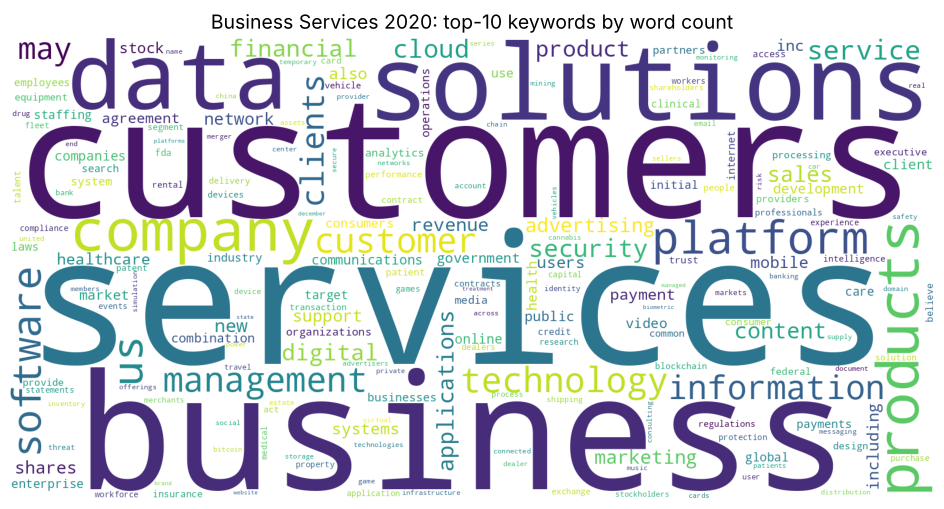

In [19]:
show_wordcloud(kw_count20, 'Business Services 2020: top-10 keywords by word count', 'output/D3_wordcloud_count_2020.png')

In [20]:
# TF-IDF keywords: how many firms have each word in their top 10
kw_tfidf20 = Counter()
for keywords in sec20['top_keywords_tfidf']:
    kw_tfidf20.update(keywords.split())
kw_tfidf20.most_common(20)

[('clients', 73),
 ('shares', 35),
 ('advertising', 35),
 ('client', 33),
 ('healthcare', 29),
 ('video', 24),
 ('consumers', 23),
 ('health', 22),
 ('clinical', 21),
 ('staffing', 18),
 ('card', 17),
 ('care', 17),
 ('privacy', 17),
 ('advertisers', 16),
 ('payments', 15),
 ('fda', 15),
 ('credit', 15),
 ('merchant', 14),
 ('trust', 14),
 ('merger', 14)]

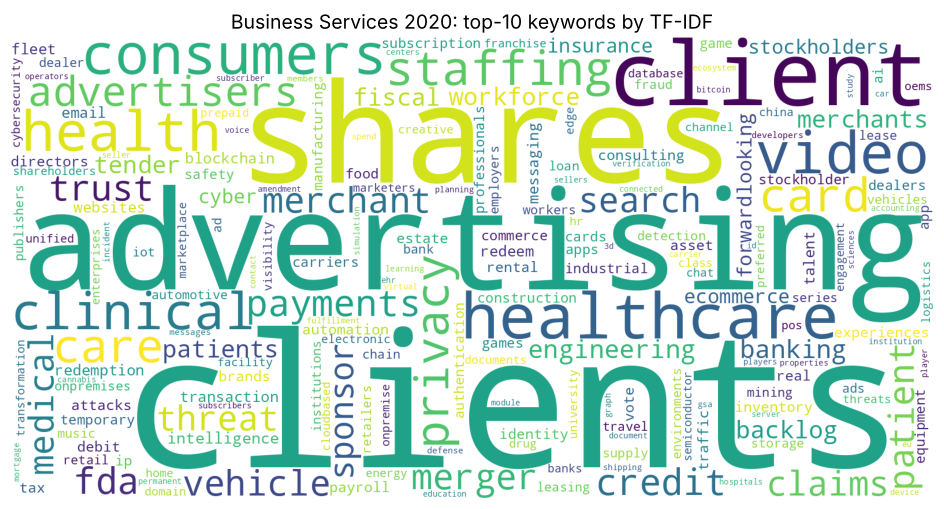

In [21]:
show_wordcloud(kw_tfidf20, 'Business Services 2020: top-10 keywords by TF-IDF', 'output/D3_wordcloud_tfidf_2020.png')

## Step E — Word embedding (2020)
### E.1 Train word2vec on the full 2020 10-K sample
The model learns from **all ~5,500 filings** (every industry), not only our sector, so it sees each word in many contexts. Training uses the **Step C cleaned text**.

Settings from class 08: 50 numbers per word (`vector_size=50`), 5 words of context on each side (`window=5`), ignore words seen fewer than 5 times (`min_count=5`), skip-gram (`sg=1`), fixed `seed=508`.

In [22]:
docs20 = []
for text in df20['item_1_clean']:
    docs20.append(text.split())
print(len(docs20), 'documents')

5481 documents


In [23]:
# about 5-10 minutes
start = time.time()
model20 = Word2Vec(docs20, vector_size=50, window=5, min_count=5, sg=1, workers=4, seed=508)
print(round(time.time() - start), 'seconds |', len(model20.wv), 'words in the vocabulary')

model20.wv.save_word2vec_format('output/w2v_2020.bin', binary=True)   # saved for Part 3
del docs20      # NEW: free up memory (the word lists are no longer needed)

456 seconds | 77381 words in the vocabulary


### E.2 Five most similar words for three keywords
Chosen after inspecting the D.3 wordclouds:
- **`privacy`**: a top TF-IDF keyword (17 firms). Data-handling firms (ad-tech, payments, HR and health data) all have to describe privacy rules.
- **`fda`**: a top TF-IDF keyword (15 firms). It shows the sector's healthcare-IT side (health software, clinical data services), which has to deal with the U.S. Food and Drug Administration.
- **`software`**: a top word-count keyword (76 firms). It is the core product of the largest SIC codes in the sector (7370–7374).

In [24]:
def similar_words(wv, word, n=5):
    '''Return the n words whose vectors are closest to word, as a DataFrame.'''
    if word not in wv:
        print(word, 'is not in the vocabulary')
        return None
    rows = []
    for other, score in wv.most_similar(word, topn=n):
        rows.append([other, round(score, 3)])
    return pd.DataFrame(rows, columns=['similar_word', 'similarity'])

In [25]:
key_words = ['privacy', 'fda', 'software']

w2v20 = {}
for word in key_words:
    w2v20[word] = similar_words(model20.wv, word)
    print(f'--- {word} (2020) ---')
    print(w2v20[word].to_string(index=False))
    print()

--- privacy (2020) ---
            similar_word  similarity
       protectionrelated       0.832
             sovereignty       0.829
                    cpni       0.827
     patientidentifiable       0.825
individuallyidentifiable       0.819

--- fda (2020) ---
 similar_word  similarity
          bla       0.817
       fdacvm       0.814
letterstofile       0.805
          pma       0.804
 resubmitting       0.801

--- software (2020) ---
similar_word  similarity
    hardware       0.891
         mfa       0.871
 serverbased       0.865
   protectid       0.863
  middleware       0.860



---
# Step F — Repeat Steps C to E for 2025
Same code and settings as 2020, applied to `2025_10K_item1_full.csv`.
## C — Text cleaning (2025)

In [26]:
df25 = pd.read_csv('data/2025_10K_item1_full.csv')
print(df25.shape)

# about 30 seconds
start = time.time()
df25['item_1_clean'] = df25['item_1'].apply(clean_text)
print(round(time.time() - start), 'seconds')
df25[['name', 'item_1_clean']].head()

(4536, 5)


23 seconds


,name,item_1_clean
0,FULLER H B CO,hb fuller company founded 1887 incorporated minnesota corporation 1915 stock traded new york stock exchange nyse tic...
1,NOVAGOLD RESOURCES INC,overview operate gold mining industry primarily focused advancing donlin gold project alaska donlin gold project hel...
2,LENNAR CORP /NEW/,overview lennar corporation one largest homebuilders united states deliveries revenues net earnings originator resid...
3,MCCORMICK & CO INC,mccormick global leader flavor manufacture market distribute spices seasoning mixes condiments flavorful products en...
4,KB HOME,general kb home one largest trusted homebuilders us building homes 65 years nearly 700000 homes built since founding...


## D — Keyword analysis (2025)
### D.1 Merge (same key and same one-row-per-firm rule as 2020)

In [27]:
bs25 = bs[bs['fyear'] == 2025]
print('sector firms in fiscal 2025:', bs25.shape[0])

sec25 = df25.merge(bs25, on=['gvkey', 'cik'], how='inner')     # NEW: merge
print('after merge:', sec25.shape[0], 'rows,', len(sec25['gvkey'].unique()), 'unique firms')

sec25['text_length'] = sec25['item_1'].str.len()
sec25 = sec25.sort_values('text_length').drop_duplicates('gvkey', keep='last')    # NEW: drop_duplicates
sec25 = sec25.sort_values('conm')
sec25.index = range(len(sec25))
print('final 2025 sample:', sec25.shape[0], 'firms (one row each)')

sector firms in fiscal 2025: 765
after merge: 513 rows, 510 unique firms
final 2025 sample: 510 firms (one row each)


### D.2 Top 10 keywords per firm (2025)

In [28]:
sec25['item_1_kw'] = sec25['item_1_clean'].apply(keyword_text)

# method 1: word counts
sec25['top_keywords_count'] = sec25['item_1_kw'].apply(get_top_keywords)

# method 2: TF-IDF (fitted on the 2025 sector filings)
vec25 = TfidfVectorizer(min_df=5, max_df=0.5)
tfidf25 = vec25.fit_transform(sec25['item_1_kw'])
words25 = vec25.get_feature_names_out()
print(tfidf25.shape, '(firms, words)')

tfidf_keywords = []
for row in range(len(sec25)):
    tfidf_keywords.append(get_tfidf_keywords(tfidf25, words25, row))
sec25['top_keywords_tfidf'] = tfidf_keywords

sec25[['conm', 'top_keywords_count', 'top_keywords_tfidf']].head(10)

(510, 10477) (firms, words)


,conm,top_keywords_count,top_keywords_tfidf
0,1606 CORP,cbd ai industry chatbot company information privacy technology also website,chatbot bot chatbots debuted isos israeli phoenix beauty solar questions
1,8X8 INC,customer platform 8x8 communications support engagement customers solutions services experience,communications cx contact voice midmarket unified messaging interaction communication programmable
2,A10 NETWORKS INC,application security a10 products defend customers solutions services applications performance,ddos defend memory ssl firewall traffic appliances attacks cores orchestrator
3,ABM INDUSTRIES INC,abm services employees solutions business service company management executive maintenance,parking facility fixedprice ireland maintenance arrangements client facilities frontline electrical
4,ACCESS NEWSWIRE INC,customers media platform access company believe investor relations new revenue,press release pr earnings communications subscription journalists rebrand nyse reseller
5,ACI WORLDWIDE INC,aci payments solutions payment customers services support products software financial,payments merchants banks billers fraud orchestration merchant accounttoaccount fiserv bill
6,ACLARION INC,pain clinical discs company nociscan data technology medical patients may,pain clinical disc surgical fda patients diagnostic imaging medical patient
7,ADEIA INC,media semiconductor patent ip including technologies companies licensing us business,semiconductor ip ott entertainment licensing innovations portfolios fundamental semiconductors rd
8,ADOBE INC,adobe customers digital experience products services customer cloud across content,adobe creative apps pdf document surfaces express pdfs generative 3d
9,ADT INC,business security customers services customer google adt state company certain,farm google residential installation smart divestiture home alarms alarm agreed


In [29]:
example_rows = []
for i in range(len(sec25)):
    example_rows.append(sec25.loc[i, 'conm'] in examples)
sec25[example_rows][['conm', 'top_keywords_count', 'top_keywords_tfidf']]

,conm,top_keywords_count,top_keywords_tfidf
8,ADOBE INC,adobe customers digital experience products services customer cloud across content,adobe creative apps pdf document surfaces express pdfs generative 3d
166,ELECTRONIC ARTS INC,services products ea players games console global entertainment business including,console games players consoles sports entertainment kelly game football pc
286,MICROSOFT CORP,information investors reports social investor website media relations including form,investors announcements post pushed news talk pertinent archives interesting responsibility
315,OMNICOM GROUP INC,marketing omnicom business media clients services client networks global merger,client merger communications experiential practice advertising clientcentric disciplines matrix sustainability
378,ROBERT HALF INC,company protiviti business robert half talent employees solutions contract clients,robert half accounting permanent professionals placement finance creative administrative consulting


**Data-quality check:** if a well-known firm's 2025 keywords look odd, compare its filing length across the two years. A very short `item_1` means the text was cut off when the source data was extracted. That is not caused by our cleaning.

In [30]:
# filing length (characters) of the example firms in both years
length_check = pd.DataFrame({
    'chars_2020': sec20[example_rows_2020]['text_length'].values,
    'chars_2025': sec25[example_rows]['text_length'].values,
}, index=sec25[example_rows]['conm'].values)
length_check

,chars_2020,chars_2025
ADOBE INC,98211,92319
ELECTRONIC ARTS INC,23515,18282
MICROSOFT CORP,60071,2332
OMNICOM GROUP INC,9209,16714
ROBERT HALF INC,16573,26456


In [31]:
sec25[['gvkey', 'cik', 'conm', 'sic', 'top_keywords_count', 'top_keywords_tfidf']].to_csv('output/sector_keywords_2025.csv', index=False)

### D.3 Wordclouds (2025)

[('services', 201), ('customers', 200), ('business', 181), ('data', 173), ('solutions', 145), ('platform', 142), ('company', 110), ('us', 106), ('products', 98), ('customer', 83), ('technology', 71), ('including', 70), ('clients', 68), ('software', 65), ('information', 61), ('management', 52), ('digital', 50), ('may', 49), ('ai', 46), ('security', 42)]


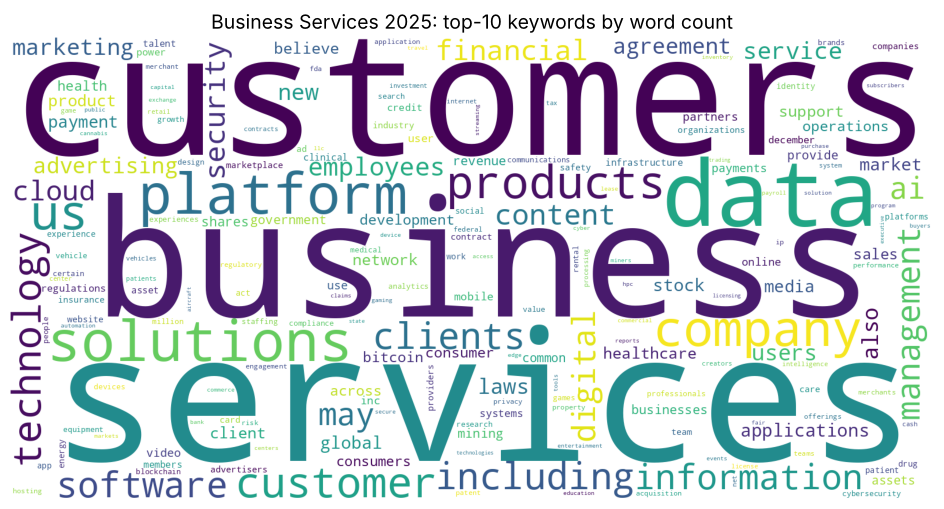

In [32]:
kw_count25 = Counter()
for keywords in sec25['top_keywords_count']:
    kw_count25.update(keywords.split())
print(kw_count25.most_common(20))
show_wordcloud(kw_count25, 'Business Services 2025: top-10 keywords by word count', 'output/D3_wordcloud_count_2025.png')

[('client', 52), ('advertising', 38), ('healthcare', 30), ('advertisers', 27), ('shares', 25), ('credit', 25), ('consumers', 25), ('payments', 23), ('clinical', 23), ('bitcoin', 23), ('card', 23), ('mining', 22), ('patient', 18), ('video', 18), ('brands', 18), ('members', 17), ('cybersecurity', 17), ('vehicle', 16), ('energy', 15), ('care', 15)]


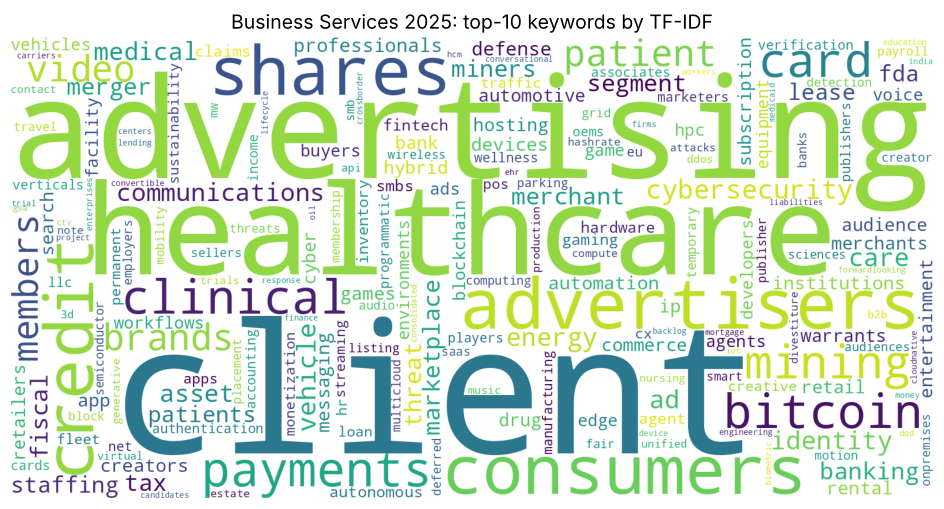

In [33]:
kw_tfidf25 = Counter()
for keywords in sec25['top_keywords_tfidf']:
    kw_tfidf25.update(keywords.split())
print(kw_tfidf25.most_common(20))
show_wordcloud(kw_tfidf25, 'Business Services 2025: top-10 keywords by TF-IDF', 'output/D3_wordcloud_tfidf_2025.png')

## E — word2vec on the full 2025 10-K sample

In [34]:
docs25 = []
for text in df25['item_1_clean']:
    docs25.append(text.split())
print(len(docs25), 'documents')

# about 5-10 minutes
start = time.time()
model25 = Word2Vec(docs25, vector_size=50, window=5, min_count=5, sg=1, workers=4, seed=508)
print(round(time.time() - start), 'seconds |', len(model25.wv), 'words in the vocabulary')

model25.wv.save_word2vec_format('output/w2v_2025.bin', binary=True)
del docs25      # NEW: free up memory

4536 documents


418 seconds | 75384 words in the vocabulary


In [35]:
w2v25 = {}
for word in key_words:
    w2v25[word] = similar_words(model25.wv, word)
    print(f'--- {word} (2025) ---')
    print(w2v25[word].to_string(index=False))
    print()

--- privacy (2025) ---
  similar_word  similarity
      ccpacpra       0.879
privacyrelated       0.855
         vcdpa       0.839
          bipa       0.837
           pii       0.837

--- fda (2025) ---
similar_word  similarity
        nada       0.847
         bla       0.839
         nda       0.832
       anada       0.830
  submission       0.815

--- software (2025) ---
similar_word  similarity
    hardware       0.894
     cerebro       0.871
     moviynt       0.871
  middleware       0.868
 cloudhosted       0.860



---
# Step F — Comparing 2020 and 2025
### F.1 Sample size

In [36]:
sample = pd.DataFrame({
    'firms in sector sample': [sec20.shape[0], sec25.shape[0]],
    'all 10-K filings (word2vec training)': [df20.shape[0], df25.shape[0]],
    'word2vec vocabulary': [len(model20.wv), len(model25.wv)],
}, index=['2020', '2025'])
sample

,firms in sector sample,all 10-K filings (word2vec training),word2vec vocabulary
2020,476,5481,77381
2025,510,4536,75384


### F.2 Most important keywords: top 20 in each year
Number in brackets = how many firms have the word in their top 10.

In [37]:
def top_list(counter, n=20):
    '''Top n words of a Counter as "word (number of firms)" strings.'''
    out = []
    for pair in counter.most_common(n):
        out.append(f'{pair[0]} ({pair[1]})')
    return out

top20 = pd.DataFrame({
    'TF-IDF 2020': top_list(kw_tfidf20),
    'TF-IDF 2025': top_list(kw_tfidf25),
    'word count 2020': top_list(kw_count20),
    'word count 2025': top_list(kw_count25),
}, index=range(1, 21))
top20

,TF-IDF 2020,TF-IDF 2025,word count 2020,word count 2025
1,clients (73),client (52),services (224),services (201)
2,shares (35),advertising (38),customers (191),customers (200)
3,advertising (35),healthcare (30),business (177),business (181)
4,client (33),advertisers (27),solutions (144),data (173)
5,healthcare (29),shares (25),data (112),solutions (145)
6,video (24),credit (25),company (112),platform (142)
7,consumers (23),consumers (25),products (109),company (110)
8,health (22),payments (23),platform (99),us (106)
9,clinical (21),clinical (23),us (86),products (98)
10,staffing (18),bitcoin (23),software (76),customer (83)


In [38]:
# which top-20 words entered or left the list
for method, c20, c25 in [('TF-IDF', kw_tfidf20, kw_tfidf25), ('word count', kw_count20, kw_count25)]:
    set20 = set([pair[0] for pair in c20.most_common(20)])
    set25 = set([pair[0] for pair in c25.most_common(20)])
    print(f'{method:10s} | new in 2025 :', sorted(set25 - set20))
    print(f'{method:10s} | dropped     :', sorted(set20 - set25))
    print()

TF-IDF     | new in 2025 : ['bitcoin', 'brands', 'cybersecurity', 'energy', 'members', 'mining', 'patient', 'vehicle']
TF-IDF     | dropped     : ['clients', 'fda', 'health', 'merchant', 'merger', 'privacy', 'staffing', 'trust']

word count | new in 2025 : ['ai', 'digital', 'including']
word count | dropped     : ['cloud', 'financial', 'service']



### F.3 Wordclouds side by side

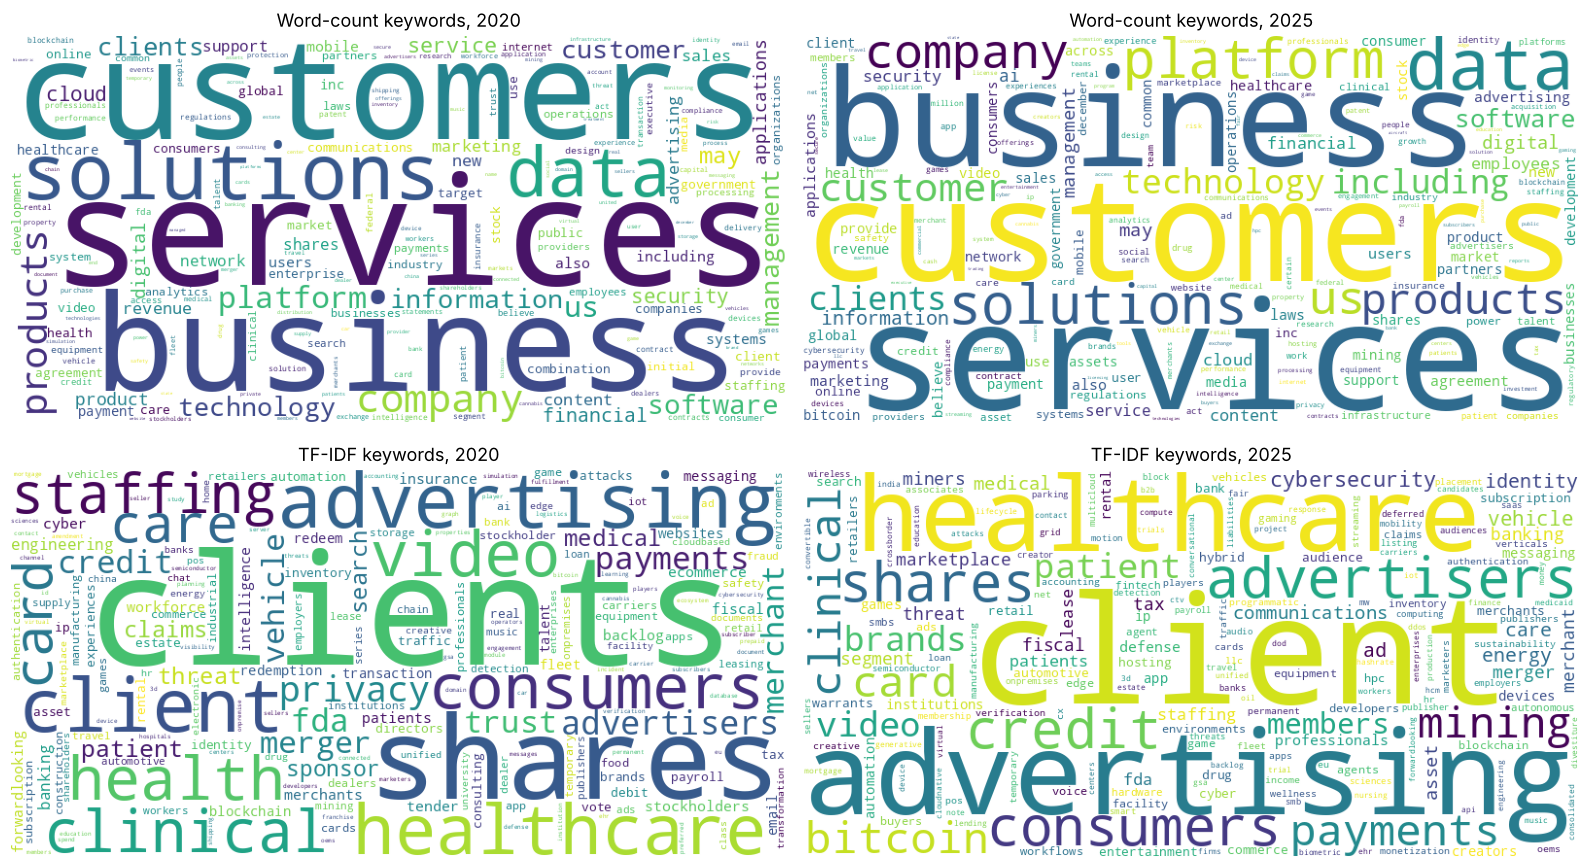

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
clouds = [(kw_count20, 'Word-count keywords, 2020'), (kw_count25, 'Word-count keywords, 2025'),
          (kw_tfidf20, 'TF-IDF keywords, 2020'), (kw_tfidf25, 'TF-IDF keywords, 2025')]
for ax, (freq, title) in zip(axes.flatten(), clouds):          # NEW: a 2x2 grid of plots
    wc = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(freq)
    ax.imshow(wc)
    ax.axis('off')
    ax.set_title(title, fontsize=13)
plt.tight_layout()
plt.savefig('output/F_wordclouds_2020_vs_2025.png', dpi=150, bbox_inches='tight')
plt.show()

### F.4 Which words rose and fell the most?
The top-10 lists only show each firm's very top words. To see broader shifts we count **every word in the sector's filings** and convert to **mentions per 10,000 words**, because 2025 has more firms and longer filings, so raw counts aren't comparable. Only words used at least 200 times in one of the years are kept, so rare words don't dominate. We use the keyword text (no bio words, no numbers) and also skip *table / contents* (page headers from "Table of Contents").

In [40]:
counts20 = Counter()
for text in sec20['item_1_kw']:
    counts20.update(text.split())
counts25 = Counter()
for text in sec25['item_1_kw']:
    counts25.update(text.split())

total20 = sum(counts20.values())
total25 = sum(counts25.values())
print('words analysed  2020:', total20, '| 2025:', total25)

rows = []
for w in set(counts20) | set(counts25):        # every word used in either year
    if w in ['table', 'contents']:
        continue
    if counts20[w] >= 200 or counts25[w] >= 200:
        rate20 = counts20[w] / total20 * 10000
        rate25 = counts25[w] / total25 * 10000
        rows.append([w, rate20, rate25, rate25 - rate20])

change = pd.DataFrame(rows, columns=['word', 'per10k_2020', 'per10k_2025', 'change'])
change = change.sort_values('change', ascending=False)
risers = change.head(15)
fallers = change.tail(15).sort_values('change')

words analysed  2020: 1669337 | 2025: 2005511


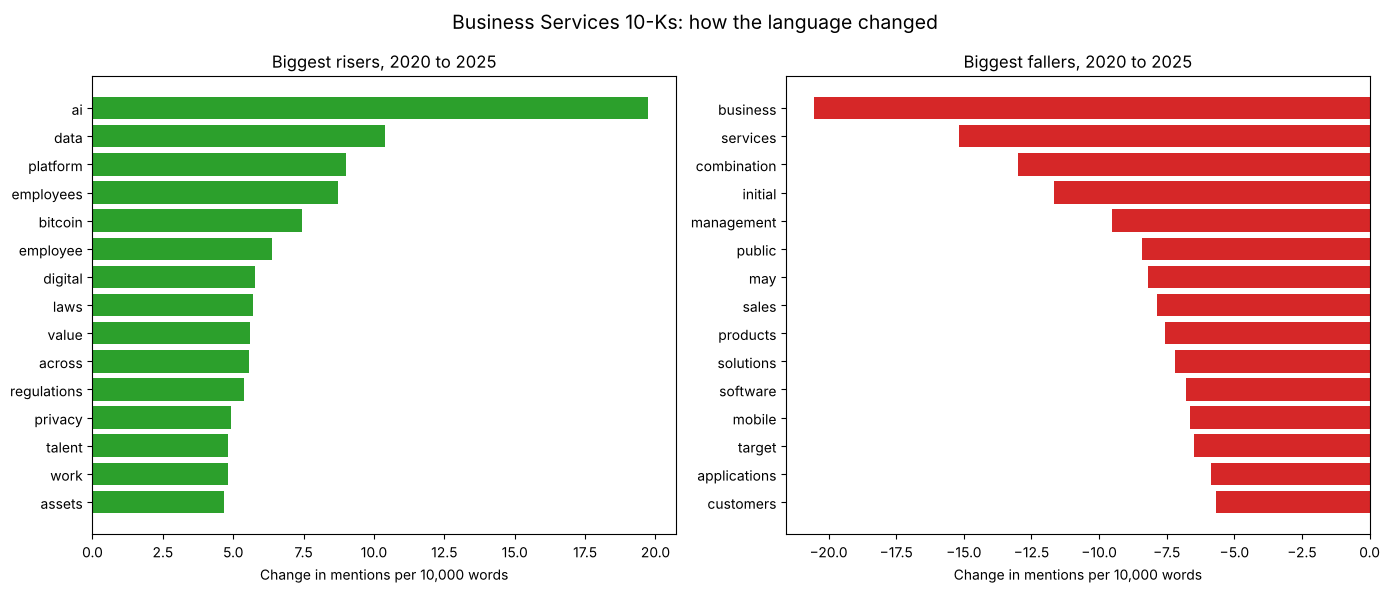

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(risers['word'][::-1], risers['change'][::-1], color='tab:green')
axes[0].set_title('Biggest risers, 2020 to 2025')
axes[0].set_xlabel('Change in mentions per 10,000 words')

axes[1].barh(fallers['word'][::-1], fallers['change'][::-1], color='tab:red')
axes[1].set_title('Biggest fallers, 2020 to 2025')
axes[1].set_xlabel('Change in mentions per 10,000 words')

plt.suptitle('Business Services 10-Ks: how the language changed', fontsize=14)
plt.tight_layout()
plt.savefig('output/F_word_risers_fallers.png', dpi=200, bbox_inches='tight')
plt.show()

**Our three keywords plus a few themes worth tracking.** For each word: mentions per 10,000 words, and the **% of sector firms whose filing mentions it at least once**.

In [42]:
def share_of_firms(df, word):
    '''% of firms whose cleaned filing contains word at least once.'''
    n = 0
    for text in df['item_1_kw']:
        if word in text.split():
            n = n + 1
    return round(n / len(df) * 100, 1)

themes = key_words + ['ai', 'generative', 'cybersecurity', 'cloud', 'covid19', 'pandemic', 'remote', 'bitcoin']
rows = []
for w in themes:
    rows.append([w,
                 round(counts20[w] / total20 * 10000, 2), round(counts25[w] / total25 * 10000, 2),
                 share_of_firms(sec20, w), share_of_firms(sec25, w)])
spotlight = pd.DataFrame(rows, columns=['word', 'per10k_2020', 'per10k_2025', '% firms 2020', '% firms 2025'])
spotlight

,word,per10k_2020,per10k_2025,% firms 2020,% firms 2025
0,privacy,8.21,13.12,45.6,65.7
1,fda,4.67,4.63,4.6,5.7
2,software,35.68,28.89,83.2,86.5
3,ai,2.79,22.52,17.6,65.3
4,generative,0.01,2.49,0.4,28.6
5,cybersecurity,2.16,4.31,19.1,36.3
6,cloud,20.24,17.50,53.4,57.5
7,covid19,1.68,0.39,13.7,11.0
8,pandemic,1.09,0.34,10.9,9.6
9,remote,1.58,2.18,25.4,32.5


### F.5 word2vec: same three keywords, 2020 model vs 2025 model

In [43]:
for word in key_words:
    both = pd.DataFrame({
        '2020 word': w2v20[word]['similar_word'].values, '2020 sim': w2v20[word]['similarity'].values,
        '2025 word': w2v25[word]['similar_word'].values, '2025 sim': w2v25[word]['similarity'].values,
    }, index=range(1, 6))
    print(f'===== {word} =====')
    print(both.to_string())
    print()

===== privacy =====
                  2020 word  2020 sim       2025 word  2025 sim
1         protectionrelated     0.832        ccpacpra     0.879
2               sovereignty     0.829  privacyrelated     0.855
3                      cpni     0.827           vcdpa     0.839
4       patientidentifiable     0.825            bipa     0.837
5  individuallyidentifiable     0.819             pii     0.837

===== fda =====
       2020 word  2020 sim   2025 word  2025 sim
1            bla     0.817        nada     0.847
2         fdacvm     0.814         bla     0.839
3  letterstofile     0.805         nda     0.832
4            pma     0.804       anada     0.830
5   resubmitting     0.801  submission     0.815

===== software =====
     2020 word  2020 sim    2025 word  2025 sim
1     hardware     0.891     hardware     0.894
2          mfa     0.871      cerebro     0.871
3  serverbased     0.865      moviynt     0.871
4    protectid     0.863   middleware     0.868
5   middleware     0.86

In [44]:
# extra: 'ai', the fastest-rising theme, in both models
for name, model in [('2020', model20), ('2025', model25)]:
    print(f'--- ai ({name} model) ---')
    result = similar_words(model.wv, 'ai')
    if result is not None:
        print(result.to_string(index=False))
    print()

--- ai (2020 model) ---
     similar_word  similarity
      explainable       0.893
     intelligence       0.890
intelligencebased       0.868
              nlp       0.866
         aidriven       0.853

--- ai (2025 model) ---
similar_word  similarity
  generative       0.938
       genai       0.922
intelligence       0.919
        aiml       0.913
     agentic       0.912



### F.6 Interpretation
**1. AI went from niche to nearly universal.** *ai* is the biggest riser of any word (2.8 → 22.5 mentions per 10,000 words). The share of sector firms mentioning it jumped from **18% to 65%**, and *generative* went from almost nobody (0.4%) to **29%** of firms. *ai* also enters the word-count top 20 in 2025, so AI is now part of how firms describe their core business, not just a risk-factor footnote. word2vec shows the *meaning* moved too: in 2020 *ai* sat next to *explainable, nlp, analytics* (AI as an analytics tool); in 2025 it sits next to *generative, genai, agentic* (AI as a product that creates content and takes actions). This lines up with the post-ChatGPT (late 2022) wave of software and service firms rebuilding their offerings around generative and agentic AI.

**2. Privacy became standard, and more specific.** The share of firms mentioning *privacy* rose from **46% to 66%** and its usage rate grew by 60%. Yet *privacy* **dropped out of the TF-IDF top 20**. That is not a contradiction: TF-IDF rewards words that set a firm apart, and once two-thirds of the sector discusses privacy it no longer sets anyone apart. The word2vec neighbours show why: in 2020 *privacy* sat next to general concepts (*protectionrelated, individuallyidentifiable, patientidentifiable*); in 2025 its closest words are **specific laws**: *ccpacpra* (California), *vcdpa* (Virginia), *bipa* (Illinois biometric privacy), plus *pii*. U.S. privacy rules have grown into a state-by-state patchwork, and firms now have to name each law they comply with. *laws* and *regulations* are also among the top risers.

**3. FDA is a stable, niche theme.** Only ~5% of sector firms mention the FDA in either year (4.6% → 5.7%), and its usage rate is flat. Its word2vec neighbours are the same kind of words in both years: drug and device approval pathways (*bla, nda, pma, submission*; 2025 adds the animal-drug versions *nada/anada*). *fda* drops out of the TF-IDF top 20 only because other themes grew around it. The healthcare-IT corner of the sector (clinical data, health software) is still there (*healthcare, clinical, patient* stay in the TF-IDF top 20) but its regulatory language hasn't changed.

**4. Software is now described as a cloud service.** *software* is still mentioned by most firms (83% → 87%), but its usage rate fell (35.7 → 28.9 per 10,000 words) and it slipped in the word-count ranking. In 2020 its neighbours included on-premise and security terms (*serverbased, mfa*); in 2025 *cloudhosted* appears. Selling software as a cloud subscription is now the default, so firms talk about *platform* (99 → 142 firms with it in their top 10) and *data* (112 → 173) instead. *cloud* itself left the word-count top 20 while the share of firms mentioning it still rose (53% → 58%): it has become a baseline expectation rather than a selling point. (Neighbours such as *cerebro* and *moviynt* are product names; word2vec trained on one year of filings picks these up, so they shouldn't be over-read.)

**5. Other notable shifts**
- **The SPAC wave faded.** *combination, initial, public, target* are among the biggest fallers, and *merger* and *trust* left the TF-IDF top 20. In 2020 many blank-check companies ("special purpose acquisition companies") registered under business-services codes and described their search for a *target* for an *initial business combination*. That boom collapsed after 2021.
- **Crypto mining and energy moved in.** *bitcoin, mining* and *energy* are new in the TF-IDF top 20 (bitcoin: 2% → 6.5% of firms). Bitcoin miners are classified as data-processing firms (SIC 7374). The 2024–25 bitcoin rally and miners' pivot to hosting AI computing (which needs a lot of power) explain the rise.
- **People and talent.** *employees, employee, talent, work* all rose. The SEC began requiring a **human-capital** section in Item 1 from November 2020, so most 2020 filings were written before that rule and 2025 filings must include it.
- **Cybersecurity** joined the TF-IDF top 20 and doubled in prevalence (19% → 36% of firms). This is consistent with the SEC's 2023 cybersecurity disclosure rules and the growing number of security-focused firms in the sector.
- **COVID-19** was mentioned by 14% of firms in the 2020 filings, which were mostly written as the pandemic began, and by about 11% in 2025, as a past event.

**Caveats:** the two samples are not the same firms (476 vs 510). word2vec results change slightly between runs and depend on each year's vocabulary. A few filings were cut off when the source data was extracted (e.g. Microsoft 2025), which affects those firms' keywords.


---
**References / AI disclosure:** Code adapted from BAIT 508 lecture notebooks (classes 07–08: keyword analysis, TF-IDF, word2vec). Claude (Anthropic) was used to help draft and structure this notebook; all outputs were run and checked by the team.